In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [25]:
df = pd.read_csv('claimants (1).csv')
display(df.head())

,CASENUM,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,5,0,0.0,1.0,0.0,50.0,34.940
1,3,1,1.0,0.0,0.0,18.0,0.891
2,66,1,0.0,1.0,0.0,5.0,0.330
3,70,0,0.0,1.0,1.0,31.0,0.037
4,96,1,0.0,1.0,0.0,30.0,0.038


In [26]:
print(f"Dataset Shape: {df.shape}")
print("\nData Types and Info:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print(f"\nNumber of Duplicate Rows: {df.duplicated().sum()}")

print("\nSummary Statistics:")
display(df.describe(include='all'))

Dataset Shape: (1340, 7)

Data Types and Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1340 entries, 0 to 1339
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   CASENUM   1340 non-null   int64  
 1   ATTORNEY  1340 non-null   int64  
 2   CLMSEX    1328 non-null   float64
 3   CLMINSUR  1299 non-null   float64
 4   SEATBELT  1292 non-null   float64
 5   CLMAGE    1151 non-null   float64
 6   LOSS      1340 non-null   float64
dtypes: float64(5), int64(2)
memory usage: 73.4 KB

Missing Values:
CASENUM       0
ATTORNEY      0
CLMSEX       12
CLMINSUR     41
SEATBELT     48
CLMAGE      189
LOSS          0
dtype: int64

Number of Duplicate Rows: 0

Summary Statistics:


,CASENUM,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
count,1340.000000,1340.000000,1328.000000,1299.000000,1292.000000,1151.000000,1340.000000
mean,11202.001493,0.488806,0.558735,0.907621,0.017028,28.414422,3.806307
std,9512.750796,0.500061,0.496725,0.289671,0.129425,20.304451,10.636903
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4177.000000,0.000000,0.000000,1.000000,0.000000,9.000000,0.400000
50%,8756.500000,0.000000,1.000000,1.000000,0.000000,30.000000,1.069500
75%,15702.500000,1.000000,1.000000,1.000000,0.000000,43.000000,3.781500
max,34153.000000,1.000000,1.000000,1.000000,1.000000,95.000000,173.604000


In [27]:
numerical_cols = ['CLMAGE', 'LOSS']
categorical_cols = ['CLMSEX', 'CLMINSUR', 'SEATBELT']
target = 'ATTORNEY'

print(f"Numerical Variables: {numerical_cols}")
print(f"Categorical Variables: {categorical_cols}")
print(f"Target Variable: {target}")

Numerical Variables: ['CLMAGE', 'LOSS']
Categorical Variables: ['CLMSEX', 'CLMINSUR', 'SEATBELT']
Target Variable: ATTORNEY


In [28]:
if 'CASENUM' in df.columns:
    df.drop('CASENUM', axis=1, inplace=True)

df.drop_duplicates(inplace=True)

for col in df.columns:
    if df[col].isnull().sum() > 0:
        if col in categorical_cols:
            df[col].fillna(df[col].mode()[0], inplace=True)
        else:
            df[col].fillna(df[col].median(), inplace=True)

print("Missing values after imputation:\n", df.isnull().sum())

Missing values after imputation:
 ATTORNEY    0
CLMSEX      0
CLMINSUR    0
SEATBELT    0
CLMAGE      0
LOSS        0
dtype: int64


In [29]:
def cap_outliers(data, col):
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    data[col] = np.where(data[col] > upper_bound, upper_bound, 
                         np.where(data[col] < lower_bound, lower_bound, data[col]))
    return data

for col in numerical_cols:
    df = cap_outliers(df, col)

for col in categorical_cols:
    df[col] = df[col].astype(int)

In [30]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
df[numerical_cols] = scaler.fit_transform(df[numerical_cols])

# Select relevant features
X = df.drop(target, axis=1)
y = df[target]

In [31]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

log_model = LogisticRegression()
log_model.fit(X_train, y_train)

print("Model Intercept:", log_model.intercept_[0])
print("\nModel Coefficients:")
for feature, coef in zip(X.columns, log_model.coef_[0]):
    print(f"{feature}: {coef}")

Model Intercept: -0.7847479964806103

Model Coefficients:
CLMSEX: 0.3342071885683679
CLMINSUR: 0.4884444093651996
SEATBELT: -0.48650948010933615
CLMAGE: 0.11769899491336973
LOSS: -1.0634265104514697


In [32]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred = log_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.6882


Confusion Matrix:
 [[ 78  55]
 [ 27 103]]


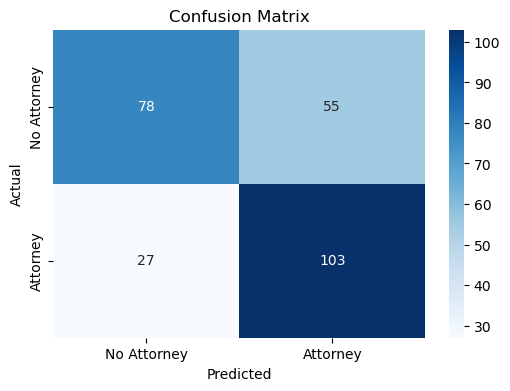

In [33]:
conf_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", conf_matrix)

plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['No Attorney', 'Attorney'], 
            yticklabels=['No Attorney', 'Attorney'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [34]:
comparison_df = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
display(comparison_df.head(10))

print("\nClassification Report:\n", classification_report(y_test, y_pred))

,Actual,Predicted
1254,0,0
76,1,1
973,1,1
435,0,0
1127,1,1
883,1,1
824,0,0
1335,1,1
352,1,1
756,0,0



Classification Report:
               precision    recall  f1-score   support

           0       0.74      0.59      0.66       133
           1       0.65      0.79      0.72       130

    accuracy                           0.69       263
   macro avg       0.70      0.69      0.69       263
weighted avg       0.70      0.69      0.69       263

